# Temporal opportunity with relaxed capacity

Each replay job may start between submission and its EASY start plus an additional delay budget. Context jobs retain their EASY starts. Every budget uses the same full-platform accounting horizon: 35 days for original and 70 days for resampled results.

The calculation optimizes jobs independently and keeps the fixed platform idle contribution. It ignores capacity conflicts, so savings are an upper bound within this start-time model, not a feasible schedule. At zero additional delay, jobs may still advance into time spent waiting under EASY.

The exact candidate starts are the allowed interval endpoints, EASY's start, intensity change times, and change times minus job runtime. Integrated footprint is linear between these candidates.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ANALYSIS = Path.cwd() if Path.cwd().name == "analysis" else Path.cwd() / "analysis"
sys.path.insert(0, str(ANALYSIS))
from helpers import experiments, platform, load_jobs, load_signals, performance, physical_totals

FIGURES = ANALYSIS / "figures"
FIGURES.mkdir(exist_ok=True)
horizons = {"original": 35 * 86400, "resampled": 70 * 86400, "alpha-sensitivity": 35 * 86400}

from helpers import relaxed_opportunity

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.alpha": 0.22,
        "pdf.fonttype": 42,
        "savefig.dpi": 300,
    }
)
COLORS = {"carbon": "#2677ad", "water": "#b85d18"}
ORDER = ["mustang_slack", "mustang_stress", "trinity_slack", "trinity_stress"]
CLASSES = ["narrow-short", "other", "wide"]
CLASS_COLORS = ["#2677ad", "#a6acb1", "#b85d18"]
WORKLOAD_COLORS = dict(zip(ORDER, ["#2677ad", "#b85d18", "#568c43", "#7c5aa1"]))

In [2]:
rows = []
for group in ["original", "resampled"]:
    config = experiments(group)
    signals = {path: load_signals(path) for path in config.environmental_trace.unique()}
    platforms = {path: platform(path) for path in config.platform.unique()}
    for _, exp in config.loc[config.variant == "easy_bf"].iterrows():
        machine = platforms[exp.platform]
        jobs = load_jobs(group, exp["name"], machine["nodes"])
        for objective, signal in signals[exp.environmental_trace].items():
            result = relaxed_opportunity(jobs, signal, machine, horizons[group], objective)
            rows.append(
                result.assign(
                    group=group, workload=exp.workload, trace=exp.trace, objective=objective
                )
            )
    print(group, "complete")
opportunity = pd.concat(rows, ignore_index=True)

original complete


resampled complete


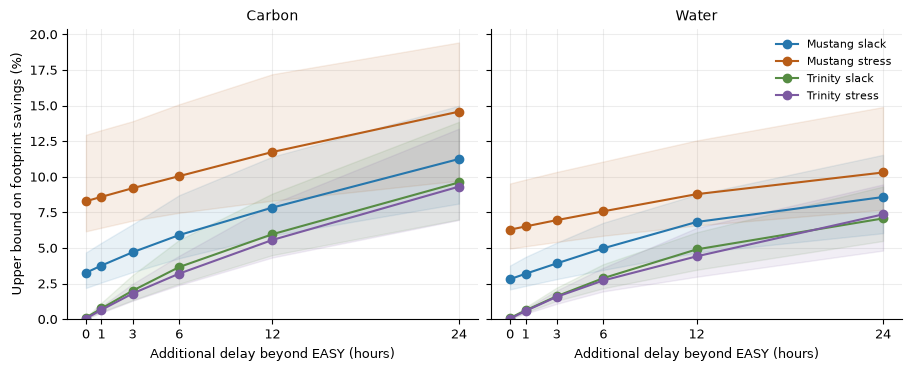

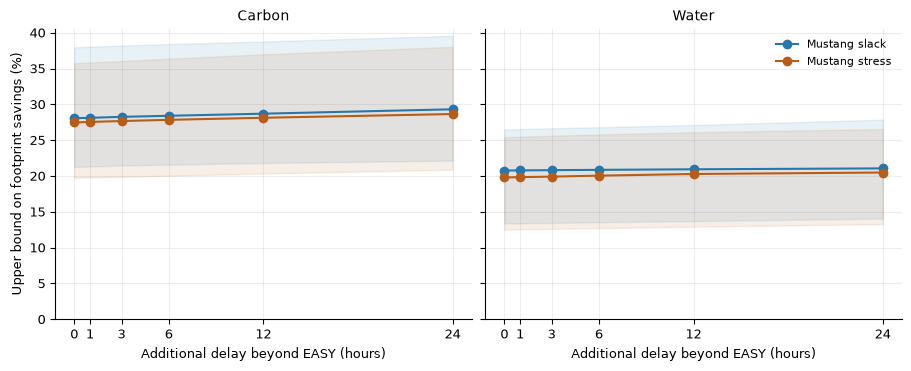

median     min      max
group     workload       objective delay_hours                          
original  mustang_slack  carbon    0.0           3.2625  0.8126   8.9226
                                   24.0         11.2492  2.7758  29.7050
                         water     0.0           2.8130  1.0065   8.1304
                                   24.0          8.5787  3.1523  24.6342
          mustang_stress carbon    0.0           8.2857  1.8330  22.2017
                                   24.0         14.5743  3.1741  34.0932
                         water     0.0           6.2871  2.0502  18.6900
                                   24.0         10.3018  3.5055  27.4117
          trinity_slack  carbon    0.0           0.1109  0.0141   0.3440
                                   24.0          9.6036  2.0561  29.8314
                         water     0.0           0.0851  0.0259   0.2455
                                   24.0          7.0756  2.1967  24.2697
          trinity_stress carbon    0.0           0.0447  0.0087   0.1541
                                   24.0          9.3090  2.2732  26.1442
                         water     0.0           0.0424  0.0058   0.1420
                                   24.0          7.3606  2.5372  21.0842
resampled mustang_slack  carbon    0.0          28.0579  7.6996  47.3742
                                   24.0         29.3085  8.2199  49.4441
                         water     0.0          20.7574  7.9597  38.2901
                                   24.0         21.0573  8.4808  39.5944
          mustang_stress carbon    0.0          27.4645  7.1365  47.1352
                                   24.0         28.6435  7.6715  49.2619
                         water     0.0          19.7885  7.6907  37.9605
                                   24.0         20.4781  8.2386  39.2571

In [3]:
for collection in ["original", "resampled"]:
    plot_data = opportunity.loc[opportunity.group == collection]
    order = [w for w in ORDER if w in set(plot_data.workload)]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained", sharey=True)
    for ax, objective in zip(axes, COLORS):
        for workload in order:
            color = WORKLOAD_COLORS[workload]
            group = (
                plot_data.loc[(plot_data.workload == workload) & (plot_data.objective == objective)]
                .groupby("delay_hours")
                .savings_pct
            )
            median = group.median()
            ax.plot(
                median.index,
                median,
                marker="o",
                label=workload.replace("_", " ").capitalize(),
                color=color,
            )
            ax.fill_between(
                median.index, group.quantile(0.25), group.quantile(0.75), color=color, alpha=0.1
            )
        ax.set(
            title=objective.capitalize(),
            xlabel="Additional delay beyond EASY (hours)",
            xticks=[0, 1, 3, 6, 12, 24],
            ylim=(0, None),
        )
    axes[0].set_ylabel("Upper bound on footprint savings (%)")
    axes[1].legend(frameon=False, fontsize=8)
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "opportunity_delay_budget" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()
display(
    opportunity.loc[opportunity.delay_hours.isin([0, 24])]
    .groupby(["group", "workload", "objective", "delay_hours"])
    .savings_pct.agg(["median", "min", "max"])
    .round(4)
)

Lines show medians and shaded bands show Q1–Q3 across 36 windows. The resampled workloads have offered load above one. Advancing jobs during their EASY waiting time creates a large relaxed opportunity, but does not provide the capacity to run them together.

Greenfilling can move context jobs or exceed these delay limits. Its difference from this bound is not necessarily an optimality gap. The bound does not cover changes in power states, job sizes, runtimes, or context jobs.